
# TS8 – Filtrado no lineal 

## Análisis y Procesamiento de Señales

### Integrantes: Catalina Wynne- Aylin Cano – Bernardita Aragón



#### Introducción

En este trabajo práctico se implementan y analizan distintas técnicas de procesamiento digital de señales aplicadas a un registro electrocardiográfico (ECG), con el objetivo de reducir las interferencias presentes y detectar los latidos cardíacos.

En la TS7 se utilizaron técnicas de filtrado lineal para atenuar las interferencias del ECG. Una de las principales dificultades fue el movimiento de la línea de base, caracterizado por oscilaciones de muy baja frecuencia (menores a 0,5 Hz) que pueden presentar amplitudes importantes y dificultar la interpretación de la señal.

En esta TS8 se estudian dos métodos para estimar y eliminar dicha interferencia: el filtro de mediana y la interpolación mediante splines cúbicos. En ambos casos, se obtiene una estimación de la línea de base que posteriormente se resta del ECG original para recuperar una señal corregida.

Además, se implementa un filtro adaptado (matched filter) para detectar los complejos QRS a partir de un patrón conocido. 

Finalmente, se evalúa el desempeño del detector mediante la comparación con los latidos de referencia, utilizando como métricas la sensibilidad y el valor predictivo positivo (VPP).


#### 1. Filtro de mediana

El movimiento de la línea de base es una interferencia de muy baja frecuencia que provoca desplazamientos lentos en la amplitud del ECG. Para reducirla, se utiliza un filtro de mediana, que es un método de filtrado no lineal.

A diferencia de un filtro de promedio, el filtro de mediana ordena los valores de una ventana de muestras y selecciona el valor central. Esto permite reducir la influencia de los picos de gran amplitud, como los complejos QRS, sin que estos modifiquen significativamente la estimación de la línea de base.

Para estimar esta interferencia se aplican dos filtros de mediana consecutivos:

1. Primera mediana (200 ms): permite atenuar los complejos QRS, que tienen una duración relativamente corta.
2. Segunda mediana (600 ms): se aplica sobre el resultado anterior para atenuar estructuras de mayor duración, principalmente las ondas P y T.

De esta manera, se obtiene una estimación de la línea de base, que luego se resta de la señal original para obtener el ECG corregido:

$$
\hat{b}[n] = \operatorname{med}_{600}\left(\operatorname{med}_{200}(s[n])\right)
$$

$$
\hat{x}[n] = s[n] - \hat{b}[n]
$$

Donde:

- $s[n]$ representa el ECG original con interferencias.
- $\hat{b}[n]$ representa la línea de base estimada.
- $\hat{x}[n]$ representa el ECG corregido.

En la implementación se utilizó una frecuencia de muestreo de 1000 Hz, por lo que las ventanas de 200 ms y 600 ms corresponden aproximadamente a 200 y 600 muestras, respectivamente. Se utilizaron tamaños impares de 201 y 601 muestras, ya que la función `medfilt` de SciPy trabaja con ventanas centradas de longitud impar.

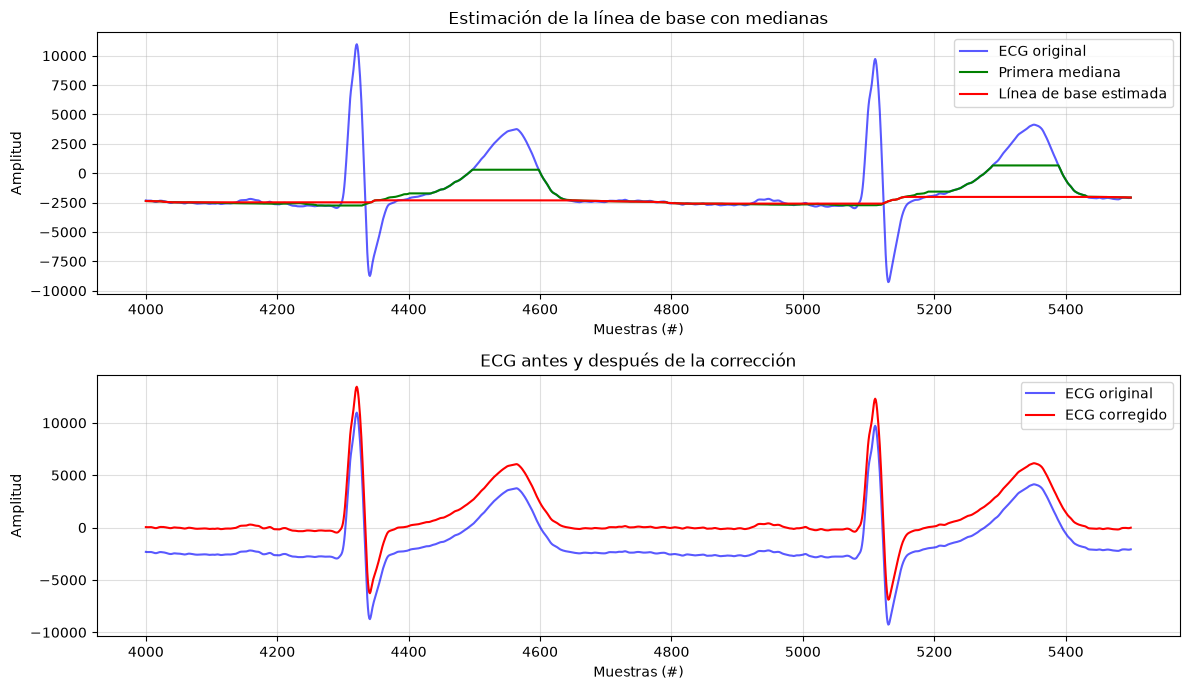

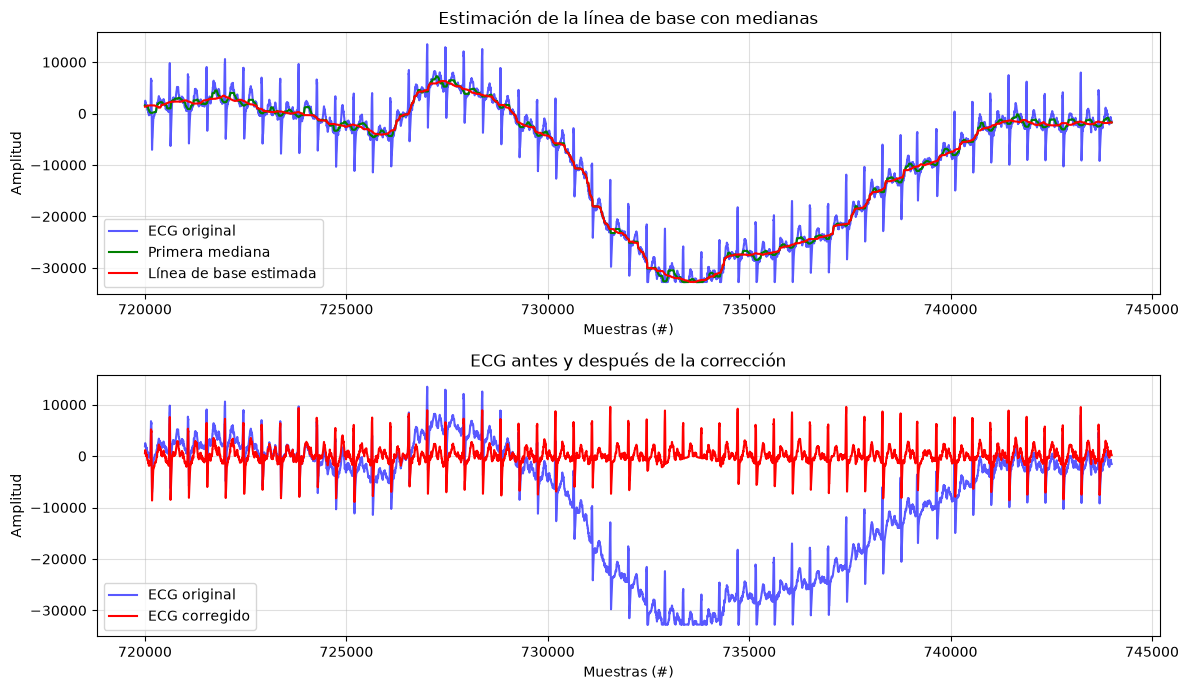

In [1]:
#importacion de modulos
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from scipy.interpolate import CubicSpline

#datos de ECG
fs = 1000          
mat = sio.loadmat('ECG_TP4.mat')
s = mat['ecg_lead'].flatten()
qrs_referencia = np.sort(mat['qrs_detections'].flatten().astype(int))
patron_qrs = mat['qrs_pattern1'].flatten()
N = len(s)
n = np.arange(N)


# 1) FILTRO DE MEDIANA
# primera ventana 200 ms, segunda unos 600 ms.
# medifilt usa impar por eso +1
ventana_1 = int(0.200 * fs) + 1
ventana_2 = int(0.600 * fs) + 1

mediana_1 = sig.medfilt(s, ventana_1)
base_mediana = sig.medfilt(mediana_1, ventana_2)
ecg_mediana = s - base_mediana

#comparo zonas
regiones = [(4000, 5500), (720000, 744000)]

for inicio, fin in regiones:
    fin = min(fin, N)
    if inicio >= fin:
        continue
    zona = np.arange(inicio, fin)

    fig, ax = plt.subplots(2, 1, figsize=(12, 7))
    ax[0].plot(zona, s[zona], color='blue', alpha=0.65, label='ECG original')
    ax[0].plot(zona, mediana_1[zona], color='green', label='Primera mediana')
    ax[0].plot(zona, base_mediana[zona], color='red', label='Línea de base estimada')
    ax[0].set_title('Estimación de la línea de base con medianas')

    ax[1].plot(zona, s[zona], color='blue', alpha=0.65, label='ECG original')
    ax[1].plot(zona, ecg_mediana[zona], color='red', label='ECG corregido')
    ax[1].set_title('ECG antes y después de la corrección')

    for eje in ax:
        eje.set_xlabel('Muestras (#)')
        eje.set_ylabel('Amplitud')
        eje.ticklabel_format(axis='x', style='plain', useOffset=False)
        eje.grid(alpha=0.4)
        eje.legend()
    plt.tight_layout()
    plt.show()

Para evaluar el comportamiento del filtro de mediana, se seleccionaron dos regiones del ECG: una con un desplazamiento relativamente pequeño de la línea de base (4000 a 5500 muestras) y otra con una interferencia mucho más pronunciada (720000 a 744000 muestras).

En la primera región se observa que la mediana de 200 ms atenúa los complejos QRS, pero todavía conserva parte de las ondas de mayor duración. Al aplicar la segunda mediana de 600 ms se obtiene una estimación más estable de la línea de base. Luego de restarla, el ECG corregido queda aproximadamente centrado en cero y conserva la forma de los latidos.

En la segunda región se observa un movimiento de línea de base de gran amplitud, que produce un desplazamiento importante de la señal original. Las dos etapas de filtrado permiten estimar esta interferencia y, al restarla, el ECG recupera una línea de base cercana a cero, manteniendo visibles los complejos cardíacos.

Por lo tanto, los resultados muestran que el filtro de mediana permite reducir significativamente el movimiento de la línea de base, tanto en regiones con interferencias pequeñas como en aquellas con desplazamientos de mayor amplitud.

#### 2. Interpolación mediante splines cúbicos

Otra técnica para estimar el movimiento de la línea de base consiste en utilizar la interpolación mediante splines cúbicos.

Este método se basa en identificar puntos del ECG donde la actividad eléctrica cardíaca es aproximadamente nula, conocidos como segmentos isoeléctricos. Se utiliza el segmento PQ, ubicado entre la onda P y el complejo QRS, donde la amplitud registrada permite aproximar el nivel de la línea de base.

Para localizar estos puntos se utilizan las posiciones de los complejos QRS proporcionadas en la variable `qrs_detections`. A partir de cada detección se selecciona una ventana comprendida entre 60 ms y 40 ms antes del QRS, buscando evitar las ondas P y Q.

Como la frecuencia de muestreo es de 1000 Hz, esta ventana corresponde a 20 muestras. En lugar de seleccionar una única muestra, se calcula el promedio de los valores dentro de cada ventana, para disminuir la influencia de las fluctuaciones rápidas y obtener una estimación más representativa del nivel de base.

De esta manera se obtiene un conjunto de puntos:

$$
S = \{(m_i,s_i) \mid i=1,2,\ldots,Q\}
$$

Donde:

- $m_i$ es la posición central de la ventana seleccionada para cada latido.
- $s_i$ es el valor promedio del ECG dentro de esa ventana.
- $Q$ es la cantidad de puntos utilizados para realizar la interpolación.

A partir de estos puntos se construye un spline cúbico, formado por polinomios de tercer grado que permiten obtener una curva continua y suave entre los puntos conocidos.

La curva se evalúa en las muestras del registro para obtener una estimación de la línea de base:

$$
\hat{b}[n] = \operatorname{spline}_3(S,n)
$$

Finalmente, al igual que en el método anterior, se resta la línea de base estimada del ECG original:

$$
\hat{x}[n] = s[n] - \hat{b}[n]
$$

Este procedimiento permite estimar el movimiento de línea de base a partir de las muestras seleccionadas del ECG. Sin embargo, su precisión depende de que los puntos elegidos representen adecuadamente el segmento PQ.


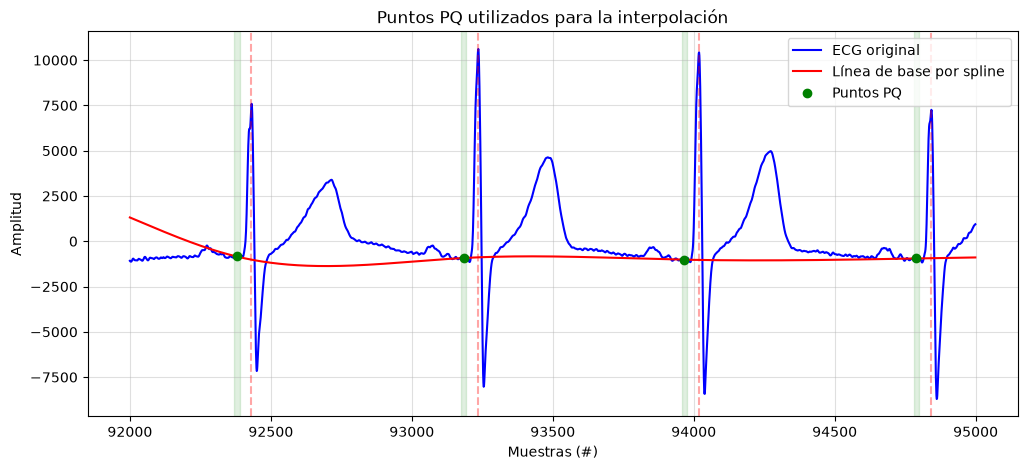

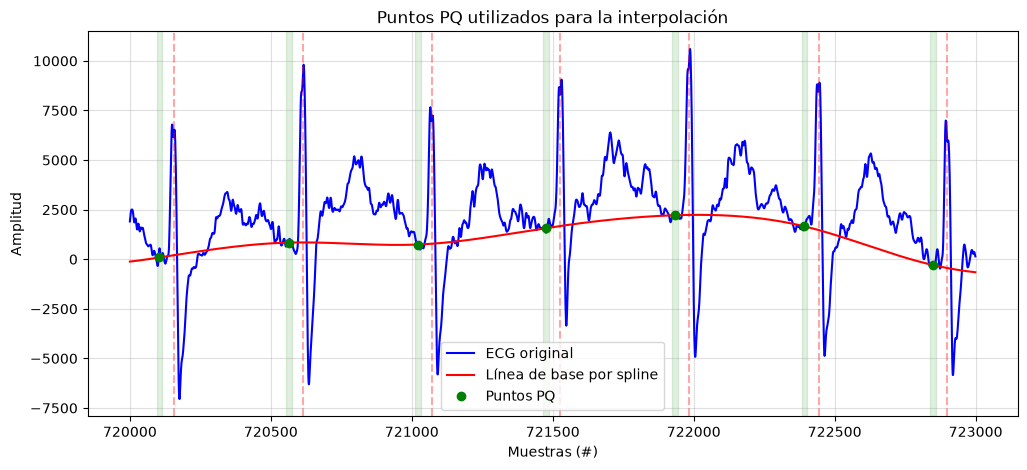

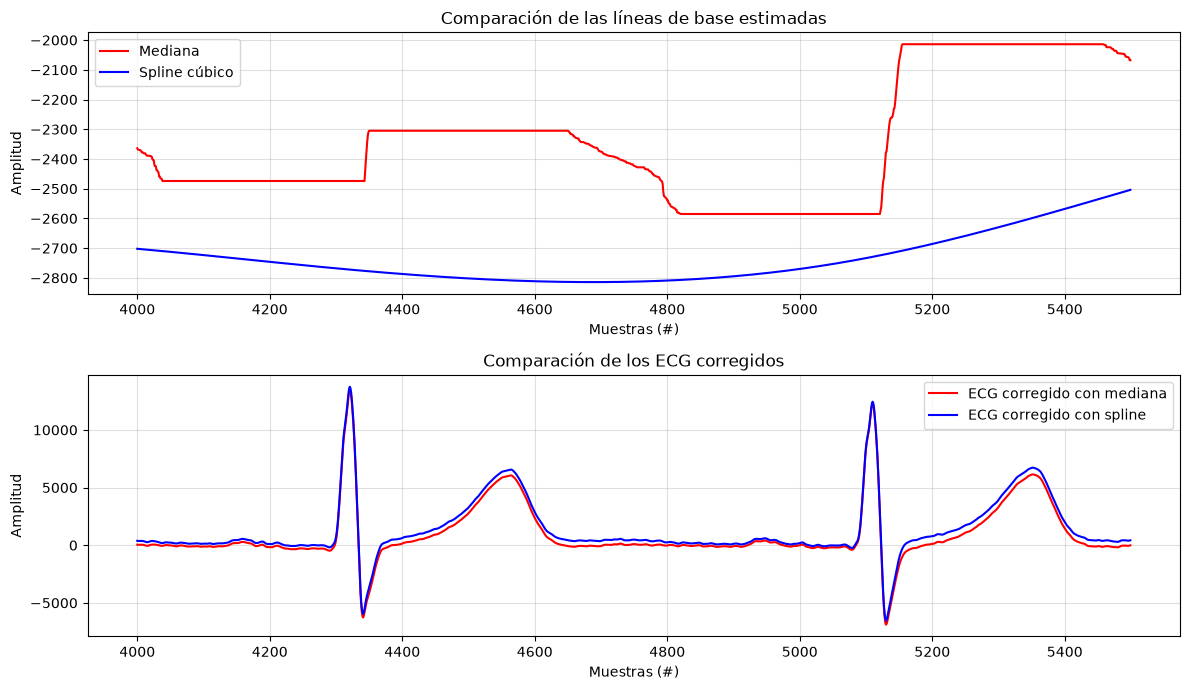

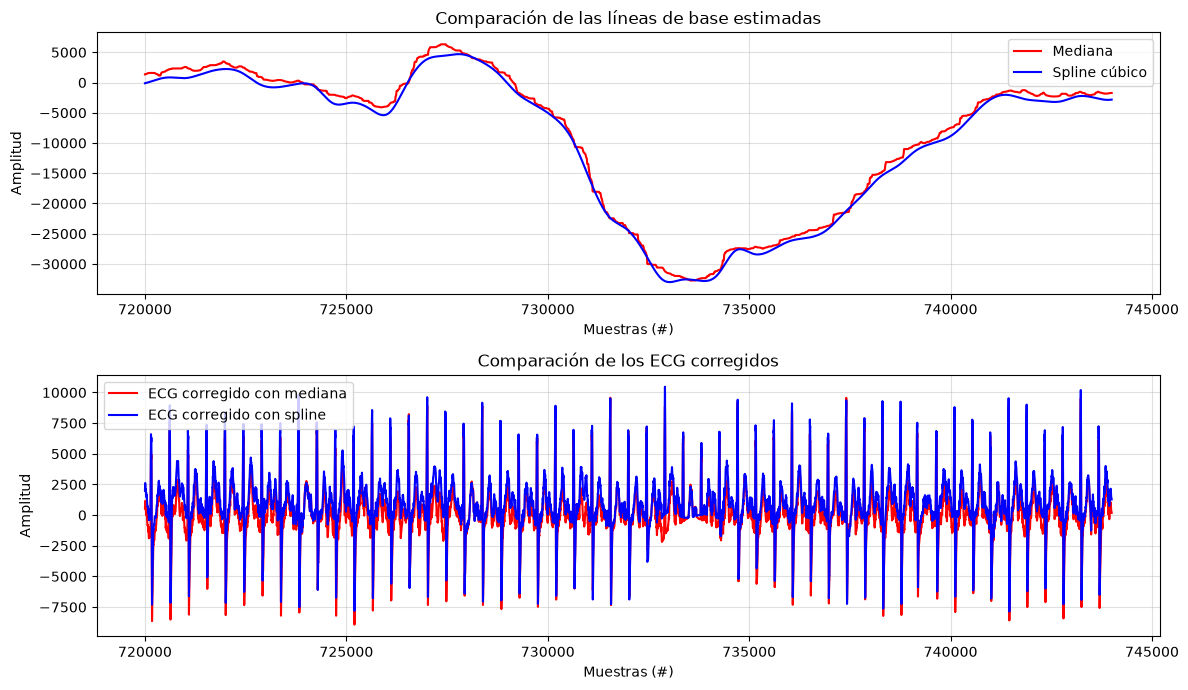

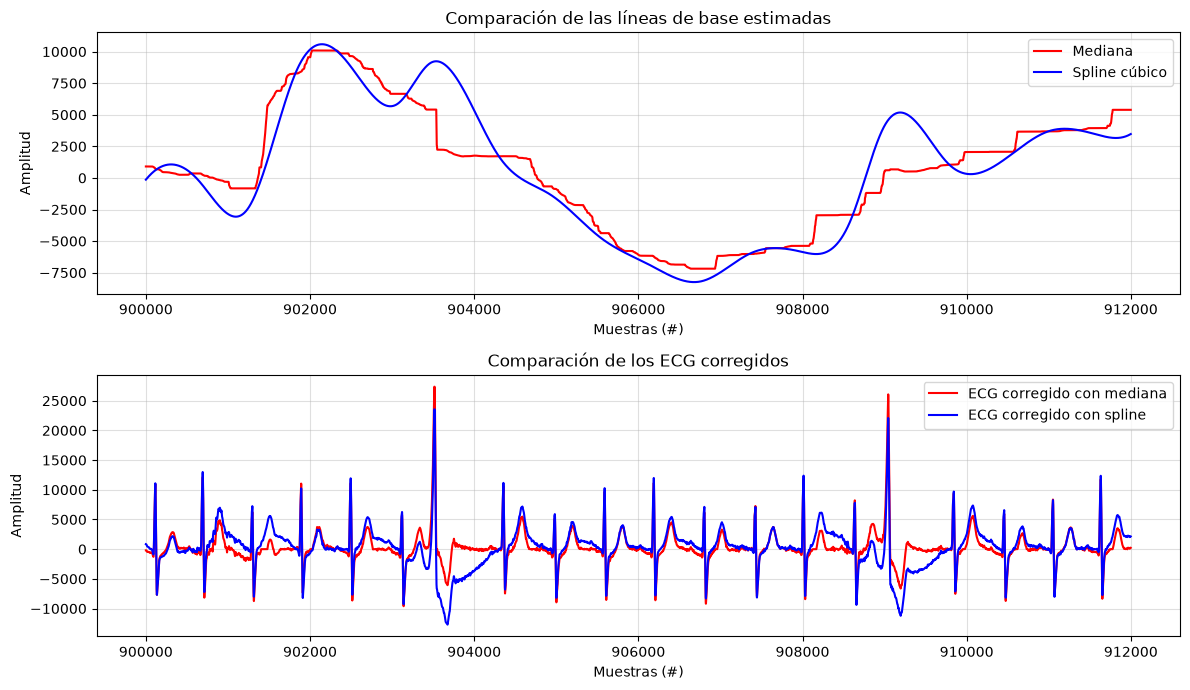

In [2]:
# 2) INTERPOLACIÓN MEDIANTE SPLINES CÚBICOS
antes_1 = int(0.060 * fs)
antes_2 = int(0.040 * fs)
inicio_pq = qrs_referencia - antes_1
fin_pq = qrs_referencia - antes_2

# elimino ventanas que queden fuera del registro.
validas = (inicio_pq >= 0) & (fin_pq <= N)
inicio_pq = inicio_pq[validas]
fin_pq = fin_pq[validas]

#promedio 20 muestras para eliminar cambios rapidos
instantes_pq = (inicio_pq + fin_pq - 1) / 2
niveles_pq = np.array([np.mean(s[a:b]) for a, b in zip(inicio_pq, fin_pq)])

# interpolo los puntos PQ y veo en ECG
curva_pq = CubicSpline(instantes_pq, niveles_pq)
base_spline = curva_pq(np.clip(n, instantes_pq[0], instantes_pq[-1]))
ecg_spline = s - base_spline

# puntos del ECG original para promedios
for inicio, fin in [(92000, 95000), (720000, 723000)]:
    fin = min(fin, N)
    if inicio >= fin:
        continue
    zona = np.arange(inicio, fin)
    seleccion = (instantes_pq >= inicio) & (instantes_pq < fin)
    qrs_zona = qrs_referencia[(qrs_referencia >= inicio) & (qrs_referencia < fin)]

    plt.figure(figsize=(12, 5))
    plt.plot(zona, s[zona], color='blue', label='ECG original')
    plt.plot(zona, base_spline[zona], color='red', label='Línea de base por spline')
    plt.plot(instantes_pq[seleccion], niveles_pq[seleccion], 'og', label='Puntos PQ')
    for q in qrs_zona:
        plt.axvline(q, color='red', linestyle='--', alpha=0.35)
        plt.axvspan(q - antes_1, q - antes_2, color='green', alpha=0.12)
    plt.title('Puntos PQ utilizados para la interpolación')
    plt.xlabel('Muestras (#)')
    plt.ylabel('Amplitud')
    plt.ticklabel_format(axis='x', style='plain', useOffset=False)
    plt.grid(alpha=0.4)
    plt.legend()
    plt.show()

# comparamos las estimaciones originales y dsp las corregidos.
for inicio, fin in [(4000, 5500), (720000, 744000), (900000, 912000)]:
    fin = min(fin, N)
    if inicio >= fin:
        continue
    zona = np.arange(inicio, fin)

    fig, ax = plt.subplots(2, 1, figsize=(12, 7))
    ax[0].plot(zona, base_mediana[zona], color='red', label='Mediana')
    ax[0].plot(zona, base_spline[zona], color='blue', label='Spline cúbico')
    ax[0].set_title('Comparación de las líneas de base estimadas')

    ax[1].plot(zona, ecg_mediana[zona], color='red', label='ECG corregido con mediana')
    ax[1].plot(zona, ecg_spline[zona], color='blue', label='ECG corregido con spline')
    ax[1].set_title('Comparación de los ECG corregidos')

    for eje in ax:
        eje.set_xlabel('Muestras (#)')
        eje.set_ylabel('Amplitud')
        eje.ticklabel_format(axis='x', style='plain', useOffset=False)
        eje.grid(alpha=0.4)
        eje.legend()
    plt.tight_layout()
    plt.show()



Para analizar el método de interpolación mediante splines cúbicos, primero se graficaron los puntos PQ seleccionados sobre el ECG original, junto con la línea de base estimada. Posteriormente, se compararon los resultados de este método con los obtenidos mediante el filtro de mediana.

-Localización de los puntos PQ:

En las regiones analizadas se observa que los puntos seleccionados se encuentran antes de cada complejo QRS y permiten seguir las variaciones de la línea de base. Sin embargo, la ubicación de los puntos depende de las detecciones QRS y del intervalo temporal elegido. Por lo tanto, no se puede garantizar que todas las ventanas correspondan exactamente al segmento isoeléctrico, lo cual puede introducir errores en la estimación.

-Comparación entre mediana y spline cúbico: 

En la región de 4000 a 5500 muestras se observa que la mediana produce una estimación con tramos horizontales y cambios bruscos, mientras que el spline genera una curva más suave y continua.

En la región de 720000 a 744000 muestras, donde existe un movimiento de línea de base de gran amplitud, ambos métodos siguen una tendencia similar y permiten reducir considerablemente el desplazamiento de la señal.

En cambio, en la región de 900000 a 912000 muestras aparecen diferencias más importantes. El spline presenta algunas oscilaciones pronunciadas que se trasladan al ECG corregido y pueden modificar su forma.



Entonces, ambos métodos permiten estimar y reducir el movimiento de línea de base. El filtro de mediana presenta una estimación menos suave, con posibles escalones, mientras que el spline cúbico produce una curva continua, aunque puede generar oscilaciones en determinadas regiones.

Por lo tanto, ninguno de los métodos resulta necesariamente superior en todas las situaciones. El desempeño del spline depende especialmente de la selección de los puntos PQ utilizados para la interpolación.



#### 3. Filtro adaptado (matched filter)

##### a) Diseño y funcionamiento del detector

El filtro adaptado es una técnica que permite identificar la presencia de un patrón conocido dentro de una señal. En este trabajo se utiliza para detectar los complejos QRS del ECG, a partir del patrón proporcionado en la variable `qrs_pattern1`.

El procedimiento consiste en desplazar el patrón sobre la señal y evaluar su semejanza con los distintos segmentos del ECG. Cuando una región presenta una forma similar al patrón QRS, la salida del filtro alcanza un valor elevado, permitiendo identificar posibles latidos.

Para implementar el filtro adaptado se utiliza como respuesta al impulso el patrón invertido temporalmente:

$$
h[n] = p[L-1-n]
$$

Donde $p[n]$ es el patrón QRS y $L$ es su cantidad de muestras. De esta manera, la convolución entre el ECG y la respuesta al impulso permite implementar una operación equivalente a la correlación con el patrón.

Antes de construir el filtro, se resta la media del patrón QRS:

$$
p_0[n] = p[n] - \overline{p}
$$

Esto permite eliminar su componente continua y reducir la influencia del nivel medio de la señal sobre la respuesta del filtro, favoreciendo la detección de las variaciones características del complejo QRS.

El filtro se aplica sobre el ECG corregido mediante interpolación por splines cúbicos. Luego, se normalizan las señales para facilitar su comparación gráfica.

La salida del filtro adaptado presenta un desplazamiento temporal respecto de los complejos QRS originales. Para estimar este retardo se considera la longitud del patrón y la posición de su máximo: $$d = (L-1)-n_R$$. Donde $n_R$ representa la posición del máximo del patrón QRS.

En nuestro caso, el retardo calculado fue de 69 muestras, equivalentes a 69 ms para una frecuencia de muestreo de 1000 Hz. Compensar este desplazamiento permite alinear los máximos de la respuesta del filtro con los complejos QRS del ECG y facilita su posterior detección.


La principal ventaja del filtro adaptado es que permite resaltar regiones de la señal que presentan una forma similar al patrón conocido, facilitando la detección de los latidos. Sin embargo, su desempeño depende de la semejanza entre el patrón utilizado y los complejos QRS presentes en el registro. Si la morfología de los latidos cambia o existen interferencias importantes, pueden aparecer detecciones incorrectas o perderse algunos latidos.


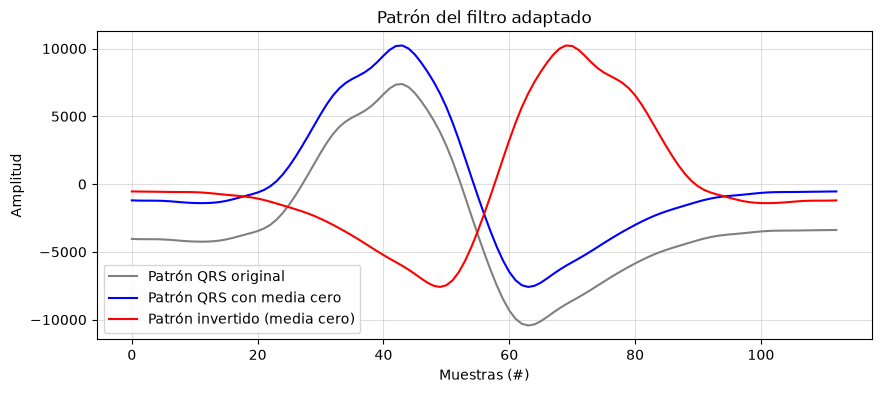

Retardo estimado del filtro adaptado: 69 muestras


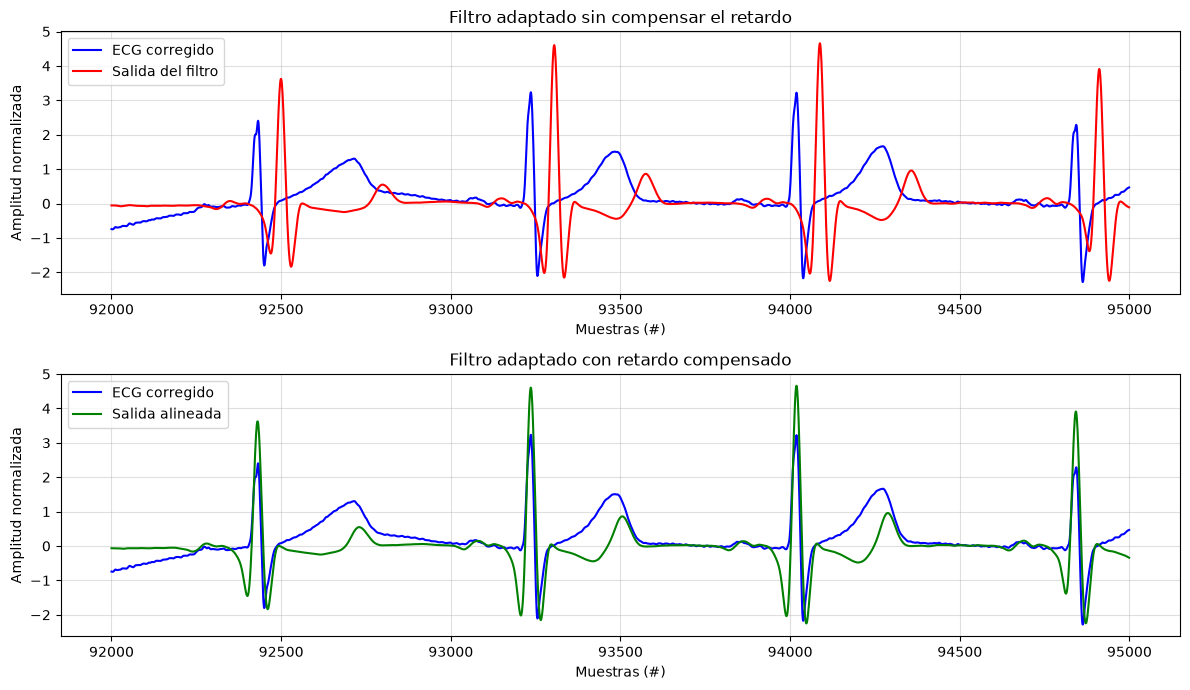

In [3]:
# 3.a) FILTRO ADAPTADO

patron_original = patron_qrs.astype(float)
patron_qrs = patron_original - np.mean(patron_original)

h = patron_qrs[::-1]
respuesta = sig.lfilter(h, 1, ecg_spline)

# normalizo para graficar ambas senales
ecg_normalizado = (ecg_spline - np.mean(ecg_spline)) / np.std(ecg_spline)
respuesta_normalizada = (respuesta - np.mean(respuesta)) / np.std(respuesta)

plt.figure(figsize=(10, 4))
plt.plot(patron_original, color='gray', label='Patrón QRS original')
plt.plot(patron_qrs, color='blue', label='Patrón QRS con media cero')
plt.plot(h, color='red', label='Patrón invertido (media cero)')
plt.title('Patrón del filtro adaptado')
plt.xlabel('Muestras (#)')
plt.ylabel('Amplitud')
plt.grid(alpha=0.4)
plt.legend()
plt.show()

#defino retardo
retardo = len(patron_qrs) - 1 - np.argmax(patron_qrs)
print('Retardo estimado del filtro adaptado:', retardo, 'muestras')

inicio = 92000
fin = min(95000, N - retardo)
if inicio < fin:
    zona = np.arange(inicio, fin)
    fig, ax = plt.subplots(2, 1, figsize=(12, 7))

    ax[0].plot(zona, ecg_normalizado[zona], color='blue', label='ECG corregido')
    ax[0].plot(zona, respuesta_normalizada[zona], color='red', label='Salida del filtro')
    ax[0].set_title('Filtro adaptado sin compensar el retardo')

    ax[1].plot(zona, ecg_normalizado[zona], color='blue', label='ECG corregido')
    ax[1].plot(zona, respuesta_normalizada[zona + retardo], color='green',
               label='Salida alineada')
    ax[1].set_title('Filtro adaptado con retardo compensado')

    for eje in ax:
        eje.set_xlabel('Muestras (#)')
        eje.set_ylabel('Amplitud normalizada')
        eje.ticklabel_format(axis='x', style='plain', useOffset=False)
        eje.grid(alpha=0.4)
        eje.legend()
    plt.tight_layout()
    plt.show()

En el primer gráfico se representa el patrón QRS original, el patrón luego de restarle su media y su versión invertida temporalmente. Podemos observar que la eliminación de la componente continua modifica el nivel medio del patrón, mientras que la inversión temporal permite obtener la respuesta al impulso utilizada en el filtro adaptado.

Al aplicar el filtro sobre el ECG corregido mediante splines cúbicos, obtenemos una señal cuyos máximos aparecen en las regiones correspondientes a los complejos QRS. Sin embargo, inicialmente estos picos se encuentran desplazados temporalmente respecto de los latidos originales.

Para corregir este desplazamiento, se calculó el retardo a partir de la longitud del patrón y de la posición de su máximo, obteniendo un valor de 69 muestras, equivalente a 69 ms.

Al compensar dicho retardo, se observa que los máximos de la respuesta del filtro quedan aproximadamente alineados con los picos R del ECG.

También se observan respuestas de menor amplitud en otras regiones de la señal, especialmente en las ondas T. Esto indica que el filtro puede responder a estructuras que presentan cierta semejanza con el patrón utilizado, lo cual representa una posible fuente de detecciones incorrectas.


##### b) Detección de latidos y evaluación del detector

Una vez obtenida la salida del filtro adaptado, se utiliza esta señal para identificar las posiciones de los complejos QRS.

En primer lugar, se calcula el módulo de la respuesta normalizada, de manera que se consideren tanto las respuestas positivas como las negativas del filtro.

Luego, se aplica un filtro de orden con una ventana de 41 muestras. Este filtro selecciona un valor según su posición dentro de las muestras ordenadas de cada ventana, permitiendo reducir pequeñas oscilaciones y obtener una señal de detección más estable.

Para localizar los posibles latidos se utiliza la función `find_peaks`, estableciendo dos condiciones:

- Altura mínima de 0,5: permite descartar picos de baja amplitud.
- Distancia mínima de 400 muestras: evita detectar varios picos demasiado próximos entre sí. Como la frecuencia de muestreo es de 1000 Hz, esta separación equivale a 400 ms.

Luego, las detecciones obtenidas se comparan con las posiciones de referencia proporcionadas en `qrs_detections`. Se considera que un latido fue detectado correctamente cuando existe una coincidencia dentro de una tolerancia de ±100 ms, sin utilizar una misma detección para más de un latido.

A partir de esta comparación se calculan:

- Verdaderos positivos (TP): latidos reales detectados correctamente.
- Falsos positivos (FP): detecciones que no corresponden a un latido de referencia dentro de la tolerancia establecida.
- Falsos negativos (FN): latidos de referencia que no fueron detectados.

El desempeño se evalúa mediante las siguientes métricas:

-Sensibilidad:indica qué porcentaje de los latidos reales fueron correctamente detectados.

$$
S = \frac{TP}{TP+FN}\cdot 100
$$

-Valor predictivo positivo (VPP): indica qué porcentaje de las detecciones realizadas corresponde a verdaderos latidos.

$$
VPP = \frac{TP}{TP+FP}\cdot 100
$$

Finalmente, se compara el desempeño utilizando el patrón QRS original y el patrón con media cero, manteniendo los mismos parámetros de detección para evaluar el efecto de eliminar la componente continua.

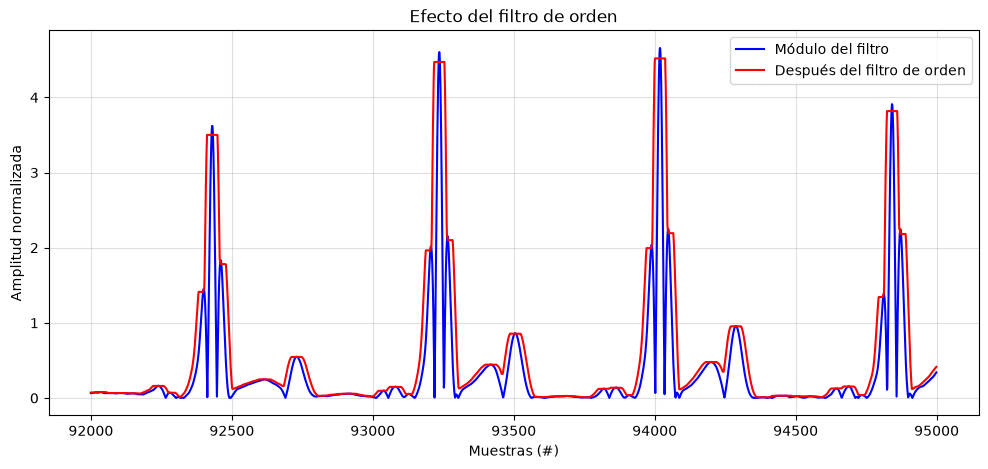

QRS de referencia: 1903
Latidos detectados: 1891


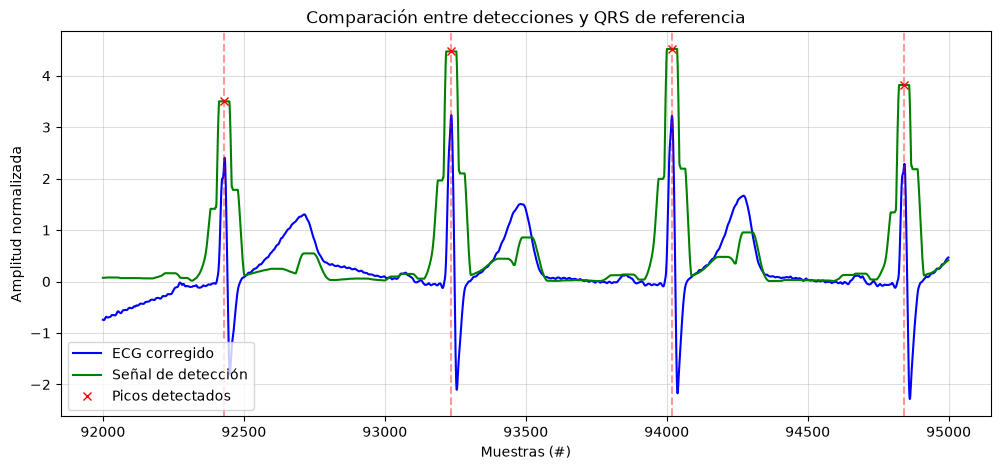

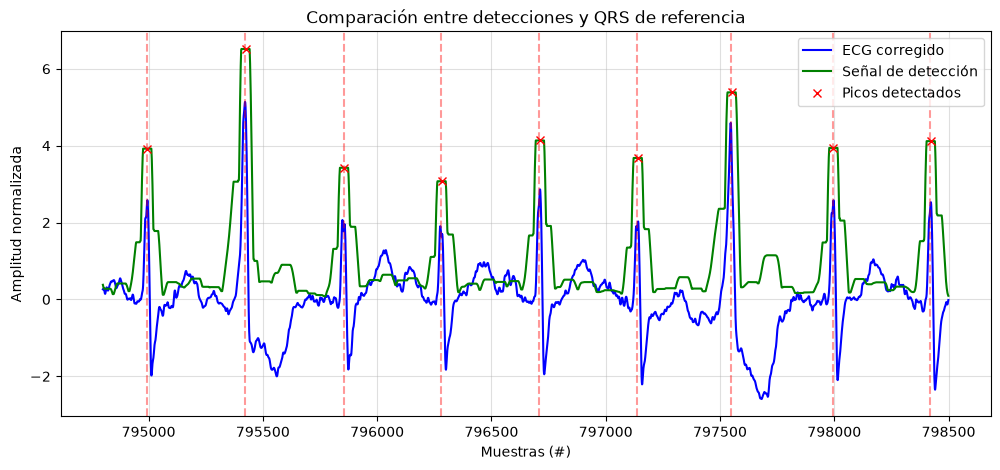

In [4]:
# 3.b) DETECCIÓN DE LATIDOS
tamano_orden = 41
rango = 36                         # 90 % de 41 muestras
separacion = int(0.400 * fs)       # separación mínima entre latidos: 400 ms
umbral = 0.5

modulo = np.abs(respuesta_normalizada)
respuesta_ordenada = sig.order_filter(modulo, np.ones(tamano_orden), rango)

# adelantamos la señal para que los picos quden cerca de los QRS.
senal_deteccion = respuesta_ordenada[retardo:]

inicio = 92000
fin = min(95000, len(senal_deteccion))
if inicio < fin:
    zona = np.arange(inicio, fin)
    plt.figure(figsize=(12, 5))
    plt.plot(zona, modulo[zona + retardo], color='blue', label='Módulo del filtro')
    plt.plot(zona, senal_deteccion[zona], color='red', label='Después del filtro de orden')
    plt.title('Efecto del filtro de orden')
    plt.xlabel('Muestras (#)')
    plt.ylabel('Amplitud normalizada')
    plt.ticklabel_format(axis='x', style='plain', useOffset=False)
    plt.grid(alpha=0.4)
    plt.legend()
    plt.show()

# busco picos con altura suficiente y separación mínima de 400 ms.
picos, propiedades = sig.find_peaks(senal_deteccion,distance=separacion, height=umbral)

print('QRS de referencia:', len(qrs_referencia))
print('Latidos detectados:', len(picos))


for inicio, fin in [(92000, 95000), (794800, 798500)]:
    fin = min(fin, len(senal_deteccion))
    if inicio >= fin:
        continue
    zona = np.arange(inicio, fin)
    encontrados = picos[(picos >= inicio) & (picos < fin)]
    referencia_zona = qrs_referencia[(qrs_referencia >= inicio) &
                                    (qrs_referencia < fin)]

    plt.figure(figsize=(12, 5))
    plt.plot(zona, ecg_normalizado[zona], color='blue', label='ECG corregido')
    plt.plot(zona, senal_deteccion[zona], color='green', label='Señal de detección')
    plt.plot(encontrados, senal_deteccion[encontrados], 'rx', label='Picos detectados')
    for q in referencia_zona:
        plt.axvline(q, color='red', linestyle='--', alpha=0.4)
    plt.title('Comparación entre detecciones y QRS de referencia')
    plt.xlabel('Muestras (#)')
    plt.ylabel('Amplitud normalizada')
    plt.ticklabel_format(axis='x', style='plain', useOffset=False)
    plt.grid(alpha=0.4)
    plt.legend()
    plt.show()

En el primer gráfico se compara el módulo de la salida del filtro adaptado con la señal obtenida después de aplicar el filtro de orden. Podemos observar que este último reduce algunas oscilaciones y genera picos más anchos y definidos.

Para evaluar visualmente el funcionamiento del detector, se seleccionaron dos regiones del ECG, en las que se representan la señal corregida, la señal de detección, los picos encontrados y las posiciones de los QRS de referencia.

En la región comprendida entre las muestras 92000 y 95000, observamos que los cuatro picos detectados coinciden aproximadamente con las posiciones de los complejos QRS. Además, si bien aparecen respuestas asociadas a otras partes del ECG, especialmente a las ondas T, estas presentan amplitudes menores que los picos principales.

En la región de 794800 a 798500 muestras también se observa una buena correspondencia entre las detecciones y los latidos de referencia, incluso cuando existen variaciones en la amplitud y la forma de los complejos cardíacos.

Estos resultados muestran que el filtro adaptado, combinado con el filtro de orden y los criterios de detección establecidos, permite identificar correctamente los complejos QRS en las regiones analizadas.

Sin embargo, la observación de estos gráficos no es suficiente para determinar el desempeño del detector en todo el registro. Por este motivo, se realiza una comparación cuantitativa con los QRS de referencia, calculando la sensibilidad y el valor predictivo positivo.


In [5]:
#METRICAS
tolerancia = int(0.100 * fs)
i = 0                            # posición en la lista de picos detectados
j = 0                            # posición en la lista de QRS reales
aciertos = 0

while i < len(picos) and j < len(qrs_referencia):
    diferencia = picos[i] - qrs_referencia[j]
    if abs(diferencia) <= tolerancia:
        aciertos += 1
        i += 1
        j += 1
    elif diferencia < 0:
        i += 1                    
    else:
        j += 1                    

TP = aciertos
FP = len(picos) - TP
FN = len(qrs_referencia) - TP
sensibilidad = 100 * TP / len(qrs_referencia)
VPP = 100 * TP / len(picos) if len(picos) > 0 else 0

print('\nMATRIZ (patrón con media cero)')
print('                 Detectado   No detectado')
print(f'QRS real         {TP:8d}   {FN:8d}')
print(f'No QRS           {FP:8d}          -')
print(f'Sensibilidad: {sensibilidad:.2f}%')
print(f'VPP: {VPP:.2f}%')


MATRIZ (patrón con media cero)
                 Detectado   No detectado
QRS real             1887         16
No QRS                  4          -
Sensibilidad: 99.16%
VPP: 99.79%


Para evaluar el desempeño del detector, se compararon los picos encontrados con los 1903 QRS de referencia, utilizando una tolerancia de ±100 ms. Mediante un ciclo `while` se recorrieron ambas listas de posiciones, contabilizando las coincidencias sin asociar una misma detección a más de un latido.

Se obtuvieron 1887 verdaderos positivos (TP), 4 falsos positivos (FP) y 16 falsos negativos (FN), sobre un total de 1891 detecciones.

A partir de estos resultados se calcularon las métricas: $$S = \frac{1887}{1887+16}\cdot100 = 99,16\%$$, $$VPP = \frac{1887}{1887+4}\cdot100 = 99,79\%$$

La sensibilidad obtenida indica que el detector identificó correctamente el 99,16 % de los latidos reales, mientras que el VPP muestra que el 99,79 % de las detecciones realizadas fueron correctas.

Estos resultados evidencian un buen desempeño del detector en el registro analizado, con una cantidad reducida de latidos no detectados y de falsas alarmas. Sin embargo, el rendimiento depende de los parámetros utilizados y de las características del ECG.


COMPARACIÓN CON LOS MISMOS CRITERIOS
Patrón            TP     FP    FN   Sensibilidad    VPP
Original        1761    122   142      92.54%     93.52%
Media cero      1887      4    16      99.16%     99.79%


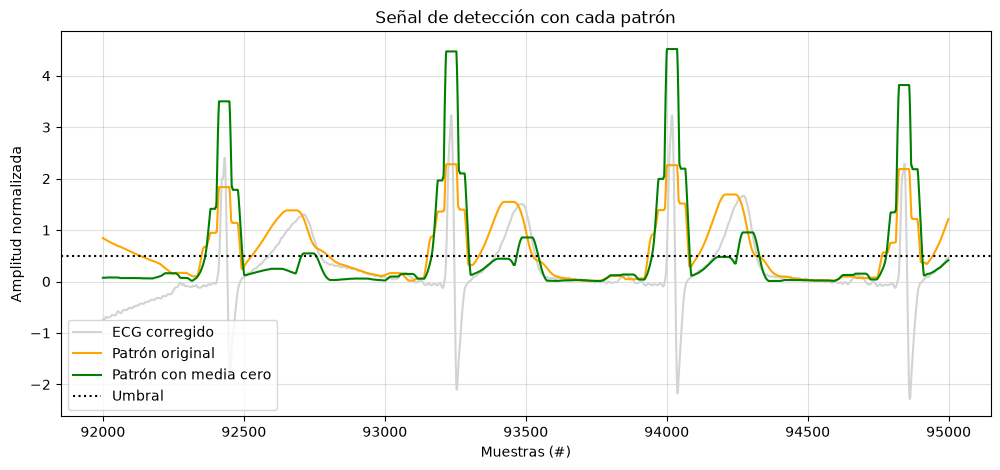

In [6]:
# COMPARACIÓN: PATRÓN ORIGINAL vs PATRÓN CON MEDIA CERO

# filtro adaptado con el patrón original sin restar la media
respuesta_orig = sig.lfilter(patron_original[::-1], 1, ecg_spline)
respuesta_orig = (respuesta_orig - np.mean(respuesta_orig)) / np.std(respuesta_orig)

# modulo + filtro de orden + compensación del retardo
modulo_orig = np.abs(respuesta_orig)
deteccion_orig = sig.order_filter(modulo_orig, np.ones(tamano_orden), rango)
deteccion_orig = deteccion_orig[retardo:]

# busco picos
picos_orig, _ = sig.find_peaks(deteccion_orig, distance=separacion, height=umbral)

#idem metricas
i = 0
j = 0
aciertos_orig = 0

while i < len(picos_orig) and j < len(qrs_referencia):
    diferencia = picos_orig[i] - qrs_referencia[j]
    if abs(diferencia) <= tolerancia:
        aciertos_orig += 1
        i += 1
        j += 1
    elif diferencia < 0:
        i += 1
    else:
        j += 1

TP_o = aciertos_orig
FP_o = len(picos_orig) - TP_o
FN_o = len(qrs_referencia) - TP_o
sens_o = 100 * TP_o / len(qrs_referencia)
VPP_o = 100 * TP_o / len(picos_orig) if len(picos_orig) > 0 else 0

print('\nCOMPARACIÓN CON LOS MISMOS CRITERIOS')
print('Patrón            TP     FP    FN   Sensibilidad    VPP')
print(f'Original      {TP_o:6d} {FP_o:6d} {FN_o:5d}   {sens_o:8.2f}%   {VPP_o:7.2f}%')
print(f'Media cero    {TP:6d} {FP:6d} {FN:5d}   {sensibilidad:8.2f}%   {VPP:7.2f}%')

# los dos patrones
inicio, fin = 92000, 95000
fin = min(fin, len(senal_deteccion))
if inicio < fin:
    zona = np.arange(inicio, fin)
    plt.figure(figsize=(12, 5))
    plt.plot(zona, ecg_normalizado[zona], color='lightgray', label='ECG corregido')
    plt.plot(zona, deteccion_orig[zona], color='orange', label='Patrón original')
    plt.plot(zona, senal_deteccion[zona], color='green', label='Patrón con media cero')
    plt.axhline(umbral, color='k', linestyle=':', label='Umbral')
    plt.title('Señal de detección con cada patrón')
    plt.xlabel('Muestras (#)')
    plt.ylabel('Amplitud normalizada')
    plt.ticklabel_format(axis='x', style='plain', useOffset=False)
    plt.grid(alpha=0.4)
    plt.legend()
    plt.show()

Para evaluar el efecto de eliminar la componente continua del patrón QRS, se comparó el desempeño del detector utilizando el patrón original y el patrón con media cero, manteniendo los mismos parámetros de detección y evaluación.

Con el patrón original se obtuvo una sensibilidad del 92,54 % y un VPP del 93,52 %, mientras que al restar la media estos valores aumentaron al 99,16 % y 99,79 %. Además, los falsos positivos disminuyeron de 122 a 4 y los falsos negativos de 142 a 16.

En el gráfico se observa que el patrón original presenta respuestas importantes tanto en los complejos QRS como en las ondas T. En cambio, al eliminar la componente continua, los picos correspondientes a los QRS se destacan más respecto de las demás estructuras de la señal. Esto ocurre porque, al restar la media, se reduce la influencia del nivel constante del patrón y el filtro responde principalmente a sus variaciones.

Por lo tanto, el patrón con media cero presentó un mejor desempeño para este ECG, aumentando la cantidad de latidos correctamente detectados y reduciendo considerablemente las falsas detecciones.



#### Conclusiones

En este trabajo práctico implementamos distintas técnicas no lineales de procesamiento digital de señales para reducir el movimiento de la línea de base del ECG y detectar los complejos QRS.

Mediante los filtros de mediana y la interpolación por splines cúbicos logramos estimar y reducir las variaciones de la línea de base. Al comparar ambos métodos, observamos que la mediana produce una estimación menos suave, mientras que el spline genera una curva continua, aunque puede presentar oscilaciones que afectan la señal corregida.

Luego, implementamos un filtro adaptado para detectar los latidos cardíacos. Los resultados demostraron la importancia del patrón utilizado, ya que al restarle su media conseguimos mejorar considerablemente el desempeño del detector.

Con esta modificación alcanzamos una sensibilidad del 99,16 % y un valor predictivo positivo del 99,79 %, reduciendo tanto los falsos positivos como los falsos negativos respecto del patrón original.

En conclusión, el trabajo nos permitió aplicar y comparar diferentes métodos de procesamiento, observar sus ventajas y limitaciones, y comprobar cómo una modificación en el diseño del filtro puede influir significativamente en los resultados obtenidos.